# Exploration — régression DPE

Chargement des données extraites ADEME + climat Open-Meteo.

In [1]:
from pathlib import Path

import pandas as pd

DATA_PATH = Path("../data/raw/dpe_n700_e500_n200.csv")

df = pd.read_csv(DATA_PATH, low_memory=False)
print(df.shape)
df.head()

(683, 128)


,_geopoint,_i,_id,_rand,adresse_ban,adresse_brut,adresse_complete_brut,annee_construction,appartement_non_visite,besoin_chauffage,...,type_installation_chauffage,type_installation_ecs,type_logement,ubat_w_par_m2_k,ventilation_posterieure_2012,version_dpe,zone_climatique,dju,t_moy_hiver,t_moy_ete
0,"43.21658904532532,2.359097060835481",29896403355010,8f6d7ec59cb91e4a79c294d5789c74bad817fd9d79ed29...,458188,25 Rue de Belfort 11000 Carcassonne,25 Rue de Belfort\nJARDINS DES REMPARTS I,25 Rue de Belfort\nJARDINS DES REMPARTS I 1100...,1979.2,0.6,49843.2,...,individuel,individuel,existant,0.62,0,2.6,H3,1636.9,8.07,23.58
1,"50.62921597929476,3.00548302344792",29896403355017,f27777e73bf74a3f5c31195229ee94ca6ddd2e4bc7c043...,913780,Rue Alexandre Desrousseaux (Lomme) 59000 Lille,RESIDENCE DU BEFFROI 4 RUE ALEXANDRE DESROUSSE...,RESIDENCE DU BEFFROI 4 RUE ALEXANDRE DESROUSSE...,1970.0,0.4,802.1,...,collectif,collectif,existant,2.37,0,2.6,H1a,2478.8,5.42,18.42
2,"43.62574995889222,6.886627040522575",29896403355020,2f6206c38ed41a3595194cc83f3d782986b4b8f91e6330...,623512,255 Avenue de Peygros 06530 Peymeinade,255 AVENUE DE PEYGROS,255 AVENUE DE PEYGROS 06530 PEYMEINADE,1985.8,1.0,32148.8,...,collectif,collectif,existant,0.57,0,2.6,H3,1362.4,9.09,24.30
3,"48.82779300100895,2.3737170147307167",29896403355024,293f3772f92794c8768a95aa8e4f48910fb657d7563d47...,866614,62 Rue du Dessous des Berges 75013 Paris,BAT 2/ 62 RUE REGNAULT - 7/11 RUE DU DESSOUS D...,BAT 2/ 62 RUE REGNAULT - 7/11 RUE DU DESSOUS D...,1954.6,1.0,1153265.1,...,collectif,individuel,existant,1.99,0,2.6,H1a,2272.0,5.79,19.98
4,"44.570591997699445,-0.25052195755074064",29896403355026,69614a21e2e3aa8df9e67bc4a09d37f207504ab2948c1b...,935258,Fleur 33490 Saint-Maixant,9 Quartier Fleur,9 Quartier Fleur 33490 ST MAIXANT,1963.0,0.4,9817.6,...,individuel,individuel,existant,0.71,0,2.6,H2c,1735.7,7.73,21.41


## Train / test + régression linéaire

Cible : `conso_5_usages_par_m2_ef` (kWh/m²).

- Variables **ordinales** (étiquette DPE/GES, qualités d'isolation, altitude, inertie, période de construction, confort été) → encodage ordinal
- Autres **qualitatives** → `get_dummies`
- Numériques conservées ; NaN imputés par la médiane du **train**

In [2]:
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

TARGET = "conso_5_usages_par_m2_ef"

# Identifiants / textes libres exclus (pas d'encodage utile)
EXCLUDE = {
    TARGET,
    "_id",
    "_score",
    "numero_dpe",
    "identifiant_ban",
    "_geopoint",
    "adresse_ban",
    "adresse_brut",
    "nom_commune_ban",
    "nom_rue_ban",
    "complement_adresse_batiment",
    "numero_voie_ban",
    "code_postal_ban",
    "code_insee_ban",
    "id_rnb",
    "numero_immatriculation",
    "nom_residence",
}

# --- Encodage ordinal (ordre métier) ---
ORDINAL_MAPS = {
    "etiquette_dpe": {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4, "F": 5, "G": 6},
    "etiquette_ges": {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4, "F": 5, "G": 6},
    "qualite_isolation_enveloppe": {
        "insuffisante": 0, "moyenne": 1, "bonne": 2, "très bonne": 3
    },
    "qualite_isolation_menuiseries": {
        "insuffisante": 0, "moyenne": 1, "bonne": 2, "très bonne": 3
    },
    "qualite_isolation_murs": {
        "insuffisante": 0, "moyenne": 1, "bonne": 2, "très bonne": 3
    },
    "qualite_isolation_plancher_bas": {
        "insuffisante": 0, "moyenne": 1, "bonne": 2, "très bonne": 3
    },
    "indicateur_confort_ete": {
        "insuffisant": 0, "moyen": 1, "bon": 2  # "Non affecté" -> NaN
    },
    "classe_altitude": {
        "inférieur à 400m": 0, "400-800m": 1, "supérieur à 800m": 2
    },
    "classe_inertie_batiment": {
        "Légère": 0, "Moyenne": 1, "Lourde": 2, "Très lourde": 3
    },
    "periode_construction": {
        "avant 1948": 0,
        "1948-1974": 1,
        "1975-1977": 2,
        "1978-1982": 3,
        "1983-1988": 4,
        "1989-2000": 5,
        "2001-2005": 6,
        "2006-2012": 7,
        "2013-2021": 8,
        "après 2021": 9,
    },
}

data = df.copy()
y = data[TARGET]
mask = y.notna()
data, y = data.loc[mask].copy(), y.loc[mask]

# Appliquer les maps ordinales
ordinal_cols = []
for col, mapping in ORDINAL_MAPS.items():
    if col in data.columns:
        data[col] = data[col].map(mapping)
        ordinal_cols.append(col)

# Colonnes à one-hot : qualitatives restantes (hors EXCLUDE / dates / ordinales)
date_like = [c for c in data.columns if c.startswith("date_")]
cat_cols = [
    c
    for c in data.select_dtypes(exclude="number").columns
    if c not in EXCLUDE and c not in date_like and c not in ORDINAL_MAPS
]

# Numériques + ordinales déjà mappées
num_cols = [
    c
    for c in data.select_dtypes(include="number").columns
    if c not in EXCLUDE
]

X = data[num_cols + cat_cols].copy()
X = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

print(f"Ordinales     : {len(ordinal_cols)} → {ordinal_cols}")
print(f"One-hot (brut): {len(cat_cols)} → {cat_cols}")
print(f"Features finales : {X_train.shape[1]}")
print(f"Train : {X_train.shape[0]} | Test : {X_test.shape[0]}")

model = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("lr", LinearRegression()),
    ]
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("MAE  :", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE :", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("R²   :", round(r2_score(y_test, y_pred), 3))

lr = model.named_steps["lr"]
features_used = model.named_steps["imputer"].get_feature_names_out()
coef = (
    pd.DataFrame({"variable": features_used, "coefficient": lr.coef_})
    .assign(abs_coef=lambda d: d["coefficient"].abs())
    .sort_values("abs_coef", ascending=False)
    .drop(columns="abs_coef")
)
print("Intercept :", round(float(lr.intercept_), 3))
print(f"Coefficients : {len(coef)}")
coef.head(20)

Ordinales     : 10 → ['etiquette_dpe', 'etiquette_ges', 'qualite_isolation_enveloppe', 'qualite_isolation_menuiseries', 'qualite_isolation_murs', 'qualite_isolation_plancher_bas', 'indicateur_confort_ete', 'classe_altitude', 'classe_inertie_batiment', 'periode_construction']
One-hot (brut): 17 → ['adresse_complete_brut', 'categorie_enr', 'code_departement_ban', 'complement_adresse_logement', 'methode_application_dpe', 'modele_dpe', 'nom_commune_brut', 'statut_geocodage', 'type_batiment', 'type_energie_n1', 'type_energie_n2', 'type_energie_principale_chauffage', 'type_energie_principale_ecs', 'type_installation_chauffage', 'type_installation_ecs', 'type_logement', 'zone_climatique']
Features finales : 1772
Train : 478 | Test : 205
MAE  : 4.69
RMSE : 9.26
R²   : 0.986
Intercept : -24.043
Coefficients : 1772


/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: divide by zero encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: overflow encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: invalid value encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/l

,variable,coefficient
55,emission_ges_5_usages_par_m2,2.468951
1760,type_installation_chauffage_individuel,-1.792207
1762,type_installation_ecs_individuel,-1.577083
71,logement_traversant,0.839840
65,etiquette_dpe,-0.826662
1738,type_energie_n1_Réseau de Chauffage urbain,0.766126
1752,type_energie_principale_chauffage_Réseau de Ch...,0.737960
1750,type_energie_principale_chauffage_Gaz naturel,-0.669902
1736,type_energie_n1_Gaz naturel,-0.669807
1758,type_energie_principale_ecs_Réseau de Chauffag...,0.652533


## OLS restreinte — variables « propriétaire »

Même cible (`conso_5_usages_par_m2_ef`), sans Ridge/Lasso.

On ne conserve que des variables **significatives** dans l’OLS précédente **et** généralement connues d’un propriétaire (étiquette DPE/GES, type d’installation, énergie principale, isolation, traversant, étages, zone climatique).

Exclus (trop techniques / leakage) : `emission_ges_*`, `conso_*_ep`, `methode_application_dpe`, `inertie_lourde`, `categorie_enr`, `type_energie_n1` (redondant avec l’énergie principale).

In [3]:
# OLS restreinte : features significatives + compréhensibles pour un propriétaire
OWNER_NUM_ORDINAL = [
    "etiquette_dpe",
    "etiquette_ges",
    "qualite_isolation_murs",
    "logement_traversant",
    "nombre_niveau_immeuble",
]
OWNER_CAT = [
    "type_installation_chauffage",
    "type_installation_ecs",
    "type_energie_principale_chauffage",
    "type_energie_principale_ecs",
    "zone_climatique",
]

# Réutiliser data / y déjà filtrés et ordinalement encodés (cellule OLS)
owner_cols = [c for c in OWNER_NUM_ORDINAL + OWNER_CAT if c in data.columns]
X_owner = data[owner_cols].copy()
X_owner = pd.get_dummies(
    X_owner,
    columns=[c for c in OWNER_CAT if c in X_owner.columns],
    drop_first=True,
    dtype=float,
)

Xo_train, Xo_test, yo_train, yo_test = train_test_split(
    X_owner, y, test_size=0.30, random_state=42
)

model_owner = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("lr", LinearRegression()),
    ]
)
model_owner.fit(Xo_train, yo_train)
yo_pred = model_owner.predict(Xo_test)

print(f"Features propriétaire : {Xo_train.shape[1]} → {list(Xo_train.columns)}")
print(f"Train : {Xo_train.shape[0]} | Test : {Xo_test.shape[0]}")
print("MAE  :", round(mean_absolute_error(yo_test, yo_pred), 2))
print("RMSE :", round(np.sqrt(mean_squared_error(yo_test, yo_pred)), 2))
print("R²   :", round(r2_score(yo_test, yo_pred), 3))

lr_owner = model_owner.named_steps["lr"]
feat_owner = model_owner.named_steps["imputer"].get_feature_names_out()
coef_owner = (
    pd.DataFrame({"variable": feat_owner, "coefficient": lr_owner.coef_})
    .assign(abs_coef=lambda d: d["coefficient"].abs())
    .sort_values("abs_coef", ascending=False)
    .drop(columns="abs_coef")
)
print("Intercept :", round(float(lr_owner.intercept_), 3))
coef_owner

Features propriétaire : 29 → ['etiquette_dpe', 'etiquette_ges', 'qualite_isolation_murs', 'logement_traversant', 'nombre_niveau_immeuble', 'type_installation_chauffage_individuel', 'type_installation_chauffage_mixte (collectif-individuel)', 'type_installation_ecs_individuel', 'type_installation_ecs_mixte (collectif-individuel)', 'type_energie_principale_chauffage_Bois – Granulés (pellets) ou briquettes', 'type_energie_principale_chauffage_Fioul domestique', 'type_energie_principale_chauffage_GPL', 'type_energie_principale_chauffage_Gaz naturel', 'type_energie_principale_chauffage_Propane', 'type_energie_principale_chauffage_Réseau de Chauffage urbain', 'type_energie_principale_chauffage_Électricité', 'type_energie_principale_ecs_GPL', 'type_energie_principale_ecs_Gaz naturel', 'type_energie_principale_ecs_Non affecté', 'type_energie_principale_ecs_Propane', 'type_energie_principale_ecs_Réseau de Chauffage urbain', 'type_energie_principale_ecs_Électricité', 'zone_climatique_H1b', 'zone_

/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


,variable,coefficient
16,type_energie_principale_ecs_GPL,137.899082
17,type_energie_principale_ecs_Gaz naturel,130.502981
21,type_energie_principale_ecs_Électricité,109.671319
18,type_energie_principale_ecs_Non affecté,106.022399
11,type_energie_principale_chauffage_GPL,-100.574898
20,type_energie_principale_ecs_Réseau de Chauffag...,82.765038
10,type_energie_principale_chauffage_Fioul domest...,77.332346
12,type_energie_principale_chauffage_Gaz naturel,-63.626075
1,etiquette_ges,32.542714
0,etiquette_dpe,26.685662


### Régularisation CV — modèle propriétaire

Même features restreintes (`Xo_train` / `Xo_test`). Imputation + scaling, puis GridSearchCV (5 folds, RMSE) pour **L2 (Ridge)**, **L1 (Lasso)** et **L1+L2 (Elastic Net)**.

In [4]:
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler

# Prétraitement sur features propriétaire uniquement
pre_owner = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
Xo_train_s = pre_owner.fit_transform(Xo_train)
Xo_test_s = pre_owner.transform(Xo_test)
feat_owner_s = pre_owner.named_steps["imputer"].get_feature_names_out()

alphas_owner = np.logspace(-3, 2, 12)
l1_ratios = [0.2, 0.5, 0.8]
print("Train scale :", Xo_train_s.shape, "| Test scale :", Xo_test_s.shape)
print("Grille alpha :", np.round(alphas_owner, 4))

Train scale : (478, 29) | Test scale : (205, 29)
Grille alpha : [1.00000e-03 2.80000e-03 8.10000e-03 2.31000e-02 6.58000e-02 1.87400e-01
 5.33700e-01 1.51990e+00 4.32880e+00 1.23285e+01 3.51119e+01 1.00000e+02]


In [5]:
# --- L2 : Ridge (features propriétaire) ---
grid_ridge_owner = GridSearchCV(
    Ridge(),
    param_grid={"alpha": alphas_owner},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
)
grid_ridge_owner.fit(Xo_train_s, yo_train)

yo_pred_ridge = grid_ridge_owner.predict(Xo_test_s)
print("L2 — Ridge")
print("  Meilleur alpha (CV) :", grid_ridge_owner.best_params_["alpha"])
print("  RMSE CV            :", round(-grid_ridge_owner.best_score_, 3))
print("  MAE  test :", round(mean_absolute_error(yo_test, yo_pred_ridge), 2))
print("  RMSE test :", round(np.sqrt(mean_squared_error(yo_test, yo_pred_ridge)), 2))
print("  R²   test :", round(r2_score(yo_test, yo_pred_ridge), 3))

/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.int

L2 — Ridge
  Meilleur alpha (CV) : 4.328761281083057
  RMSE CV            : 35.556
  MAE  test : 22.18
  RMSE test : 28.1
  R²   test : 0.87


/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.int

In [6]:
# --- L1 : Lasso (features propriétaire) ---
grid_lasso_owner = GridSearchCV(
    Lasso(max_iter=20000, random_state=42),
    param_grid={"alpha": alphas_owner},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
)
grid_lasso_owner.fit(Xo_train_s, yo_train)

yo_pred_lasso = grid_lasso_owner.predict(Xo_test_s)
print("L1 — Lasso")
print("  Meilleur alpha (CV) :", grid_lasso_owner.best_params_["alpha"])
print("  RMSE CV            :", round(-grid_lasso_owner.best_score_, 3))
print("  MAE  test :", round(mean_absolute_error(yo_test, yo_pred_lasso), 2))
print("  RMSE test :", round(np.sqrt(mean_squared_error(yo_test, yo_pred_lasso)), 2))
print("  R²   test :", round(r2_score(yo_test, yo_pred_lasso), 3))
print(
    "  Coefs non nuls :",
    int(np.sum(np.abs(grid_lasso_owner.best_estimator_.coef_) > 1e-8)),
    "/",
    len(feat_owner_s),
)

L1 — Lasso
  Meilleur alpha (CV) : 0.5336699231206307
  RMSE CV            : 35.624
  MAE  test : 21.99
  RMSE test : 27.44
  R²   test : 0.876
  Coefs non nuls : 23 / 29


/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.

In [7]:
# --- L1 + L2 : Elastic Net (features propriétaire) ---
grid_enet_owner = GridSearchCV(
    ElasticNet(max_iter=20000, random_state=42),
    param_grid={"alpha": alphas_owner, "l1_ratio": l1_ratios},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
)
grid_enet_owner.fit(Xo_train_s, yo_train)

yo_pred_enet = grid_enet_owner.predict(Xo_test_s)
print("L1+L2 — Elastic Net")
print("  Meilleurs params (CV) :", grid_enet_owner.best_params_)
print("  RMSE CV              :", round(-grid_enet_owner.best_score_, 3))
print("  MAE  test :", round(mean_absolute_error(yo_test, yo_pred_enet), 2))
print("  RMSE test :", round(np.sqrt(mean_squared_error(yo_test, yo_pred_enet)), 2))
print("  R²   test :", round(r2_score(yo_test, yo_pred_enet), 3))
print(
    "  Coefs non nuls :",
    int(np.sum(np.abs(grid_enet_owner.best_estimator_.coef_) > 1e-8)),
    "/",
    len(feat_owner_s),
)

/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.

L1+L2 — Elastic Net
  Meilleurs params (CV) : {'alpha': np.float64(0.02310129700083159), 'l1_ratio': 0.2}
  RMSE CV              : 35.555
  MAE  test : 22.22
  RMSE test : 28.14
  R²   test : 0.87
  Coefs non nuls : 29 / 29


/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.

In [8]:
# --- Synthèse : meilleure pénalisation (RMSE CV) ---
owner_penalties = {
    "L2 (Ridge)": grid_ridge_owner,
    "L1 (Lasso)": grid_lasso_owner,
    "L1+L2 (Elastic Net)": grid_enet_owner,
}

comparison_owner = pd.DataFrame(
    [
        {
            "pénalisation": name,
            "rmse_cv": -grid.best_score_,
            "params": grid.best_params_,
            "mae_test": mean_absolute_error(yo_test, grid.predict(Xo_test_s)),
            "rmse_test": np.sqrt(mean_squared_error(yo_test, grid.predict(Xo_test_s))),
            "r2_test": r2_score(yo_test, grid.predict(Xo_test_s)),
        }
        for name, grid in owner_penalties.items()
    ]
).sort_values("rmse_cv")

best_name = comparison_owner.iloc[0]["pénalisation"]
best_grid = owner_penalties[best_name]
best_est = best_grid.best_estimator_

print("Comparaison (triée par RMSE CV) :")
print(comparison_owner.round(3).to_string(index=False))

print("\n>>> Meilleure pénalisation :", best_name)
print(">>> Hyperparamètres        :", best_grid.best_params_)
print(">>> RMSE CV                :", round(-best_grid.best_score_, 3))
print(">>> Intercept              :", round(float(best_est.intercept_), 3))

coef_best_owner = (
    pd.DataFrame(
        {"variable": feat_owner_s, "coefficient": best_est.coef_}
    )
    .assign(abs_coef=lambda d: d["coefficient"].abs())
    .sort_values("abs_coef", ascending=False)
    .drop(columns="abs_coef")
)
print(f"\nCoefficients ({best_name}) :")
coef_best_owner

Comparaison (triée par RMSE CV) :
       pénalisation  rmse_cv                                          params  mae_test  rmse_test  r2_test
L1+L2 (Elastic Net)   35.555 {'alpha': 0.02310129700083159, 'l1_ratio': 0.2}    22.221     28.135    0.870
         L2 (Ridge)   35.556                    {'alpha': 4.328761281083057}    22.181     28.095    0.870
         L1 (Lasso)   35.624                   {'alpha': 0.5336699231206307}    21.989     27.438    0.876

>>> Meilleure pénalisation : L1+L2 (Elastic Net)
>>> Hyperparamètres        : {'alpha': np.float64(0.02310129700083159), 'l1_ratio': 0.2}
>>> RMSE CV                : 35.555
>>> Intercept              : 124.66

Coefficients (L1+L2 (Elastic Net)) :


/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.

,variable,coefficient
1,etiquette_ges,40.192456
0,etiquette_dpe,34.998090
17,type_energie_principale_ecs_Gaz naturel,18.872198
12,type_energie_principale_chauffage_Gaz naturel,-16.888808
21,type_energie_principale_ecs_Électricité,12.694864
14,type_energie_principale_chauffage_Réseau de Ch...,9.491692
18,type_energie_principale_ecs_Non affecté,9.176323
5,type_installation_chauffage_individuel,-8.656962
2,qualite_isolation_murs,-8.526003
11,type_energie_principale_chauffage_GPL,-6.804829


## Régularisation : 3 expériences séparées

Même `X_train` / `X_test` (encodage ordinal + dummies).

1. Prétraitement commun (imputation + scaling)
2. **L2 — Ridge** : meilleur `alpha` en CV, puis MAE / RMSE / R² test
3. **L1 — Lasso** : idem
4. **L1+L2 — Elastic Net** : meilleur `(alpha, l1_ratio)` en CV, puis métriques test

Tu compares ensuite et tu choisis la méthode à garder.

In [9]:
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler

# Prétraitement commun (fit sur le train uniquement)
pre = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
X_train_s = pre.fit_transform(X_train)
X_test_s = pre.transform(X_test)
feature_names = pre.named_steps["imputer"].get_feature_names_out()

alphas = np.logspace(-3, 2, 12)  # grille commune d'alpha
print("Train scale :", X_train_s.shape, "| Test scale :", X_test_s.shape)
print("Grille alpha :", np.round(alphas, 4))


Train scale : (478, 1772) | Test scale : (205, 1772)
Grille alpha : [1.00000e-03 2.80000e-03 8.10000e-03 2.31000e-02 6.58000e-02 1.87400e-01
 5.33700e-01 1.51990e+00 4.32880e+00 1.23285e+01 3.51119e+01 1.00000e+02]


### L2 — Ridge

Pénalité \(\sum b_j^2\). Cherche le meilleur `alpha` en validation croisée (5 folds, RMSE).


In [10]:
# --- L2 : Ridge ---
grid_ridge = GridSearchCV(
    Ridge(),
    param_grid={"alpha": alphas},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
)
grid_ridge.fit(X_train_s, y_train)

print("Meilleur alpha (CV) :", grid_ridge.best_params_["alpha"])
print("RMSE CV            :", round(-grid_ridge.best_score_, 3))

y_pred_ridge = grid_ridge.predict(X_test_s)
print("MAE  test :", round(mean_absolute_error(y_test, y_pred_ridge), 2))
print("RMSE test :", round(np.sqrt(mean_squared_error(y_test, y_pred_ridge)), 2))
print("R²   test :", round(r2_score(y_test, y_pred_ridge), 3))
print("Coefs non nuls :", int(np.sum(np.abs(grid_ridge.best_estimator_.coef_) > 1e-8)), "/", len(feature_names))


/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/thomasfonferrier/Documents/SISE/python-ML

Meilleur alpha (CV) : 0.5336699231206307
RMSE CV            : 35.918
MAE  test : 23.76
RMSE test : 42.11
R²   test : 0.709
Coefs non nuls : 1337 / 1772


/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: divide by zero encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: overflow encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: invalid value encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/l

### L1 — Lasso

Pénalité \(\sum |b_j|\). Cherche le meilleur `alpha` en CV ; peut annuler des coefficients.


In [11]:
# --- L1 : Lasso ---
grid_lasso = GridSearchCV(
    Lasso(max_iter=20000, random_state=42),
    param_grid={"alpha": alphas},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
)
grid_lasso.fit(X_train_s, y_train)

print("Meilleur alpha (CV) :", grid_lasso.best_params_["alpha"])
print("RMSE CV            :", round(-grid_lasso.best_score_, 3))

y_pred_lasso = grid_lasso.predict(X_test_s)
print("MAE  test :", round(mean_absolute_error(y_test, y_pred_lasso), 2))
print("RMSE test :", round(np.sqrt(mean_squared_error(y_test, y_pred_lasso)), 2))
print("R²   test :", round(r2_score(y_test, y_pred_lasso), 3))
print("Coefs non nuls :", int(np.sum(np.abs(grid_lasso.best_estimator_.coef_) > 1e-8)), "/", len(feature_names))


/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: divide by zero encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: overflow encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: invalid value encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/l

Meilleur alpha (CV) : 0.5336699231206307
RMSE CV            : 11.423
MAE  test : 4.4
RMSE test : 8.19
R²   test : 0.989
Coefs non nuls : 107 / 1772


/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: divide by zero encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: overflow encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: invalid value encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/l

### L1 + L2 — Elastic Net

Mélange Lasso et Ridge. Cherche le meilleur couple `(alpha, l1_ratio)` en CV.


In [12]:
# --- L1 + L2 : Elastic Net ---
grid_enet = GridSearchCV(
    ElasticNet(max_iter=20000, random_state=42),
    param_grid={"alpha": alphas, "l1_ratio": [0.2, 0.5, 0.8]},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
)
grid_enet.fit(X_train_s, y_train)

print("Meilleurs paramètres (CV) :", grid_enet.best_params_)
print("RMSE CV                  :", round(-grid_enet.best_score_, 3))

y_pred_enet = grid_enet.predict(X_test_s)
print("MAE  test :", round(mean_absolute_error(y_test, y_pred_enet), 2))
print("RMSE test :", round(np.sqrt(mean_squared_error(y_test, y_pred_enet)), 2))
print("R²   test :", round(r2_score(y_test, y_pred_enet), 3))
print("Coefs non nuls :", int(np.sum(np.abs(grid_enet.best_estimator_.coef_) > 1e-8)), "/", len(feature_names))


/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: divide by zero encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: overflow encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: invalid value encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/l

Meilleurs paramètres (CV) : {'alpha': np.float64(0.02310129700083159), 'l1_ratio': 0.8}
RMSE CV                  : 21.905
MAE  test : 11.89
RMSE test : 20.77
R²   test : 0.929
Coefs non nuls : 982 / 1772


/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: divide by zero encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: overflow encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: invalid value encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/l

## ACM — Analyse des Correspondances Multiples

ACM sur les variables **qualitatives non ordinales** (hors étiquettes DPE/GES, qualités d'isolation, altitude, inertie, période de construction, confort d'été — déjà traitées en ordinal).

Objectif : résumer les associations entre modalités (énergie, type de bâtiment, zone climatique, etc.) sur un plan factoriel.


Variables qualitatives non ordinales retenues (11) :
['modele_dpe', 'statut_geocodage', 'type_batiment', 'type_energie_n1', 'type_energie_n2', 'type_energie_principale_chauffage', 'type_energie_principale_ecs', 'type_installation_chauffage', 'type_installation_ecs', 'type_logement', 'zone_climatique']

Inertie / valeurs propres :


/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ =

,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,0.351,8.77%,8.77%
1,0.347,8.68%,17.44%
2,0.277,6.92%,24.36%
3,0.256,6.41%,30.77%
4,0.253,6.33%,37.10%


/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/prince/ca.py:159: RuntimeWarning: divide by zero encountered in matmul
  data=X @ sparse.diags(self.col_masses_.to_numpy() ** -0.5) @ self.svd_.V.T,
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/prince/ca.py:159: RuntimeWarning: overflow encountered in matmul
  data=X @ sparse.diags(self.col_masses_.to_numpy() ** -0.5) @ self.svd_.V.T,
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/prince/ca.py:159: RuntimeWarning: invalid value encountered in matmul
  data=X @ sparse.diags(self.col_masses_.to_numpy() ** -0.5) @ self.svd_.V.T,
/Users/thomasfonferrier/Documents/SISE/python-ML-asardellitti/.venv/lib/python3.9/site-packages/prince/ca.py:222: RuntimeWarning: divide by zero encountered in matmul
  data=X @ sparse.diags(self.row_masses_.to_numpy() ** -0.5) @ self.svd_.U,
/Users/thomasfonferrier/Docum

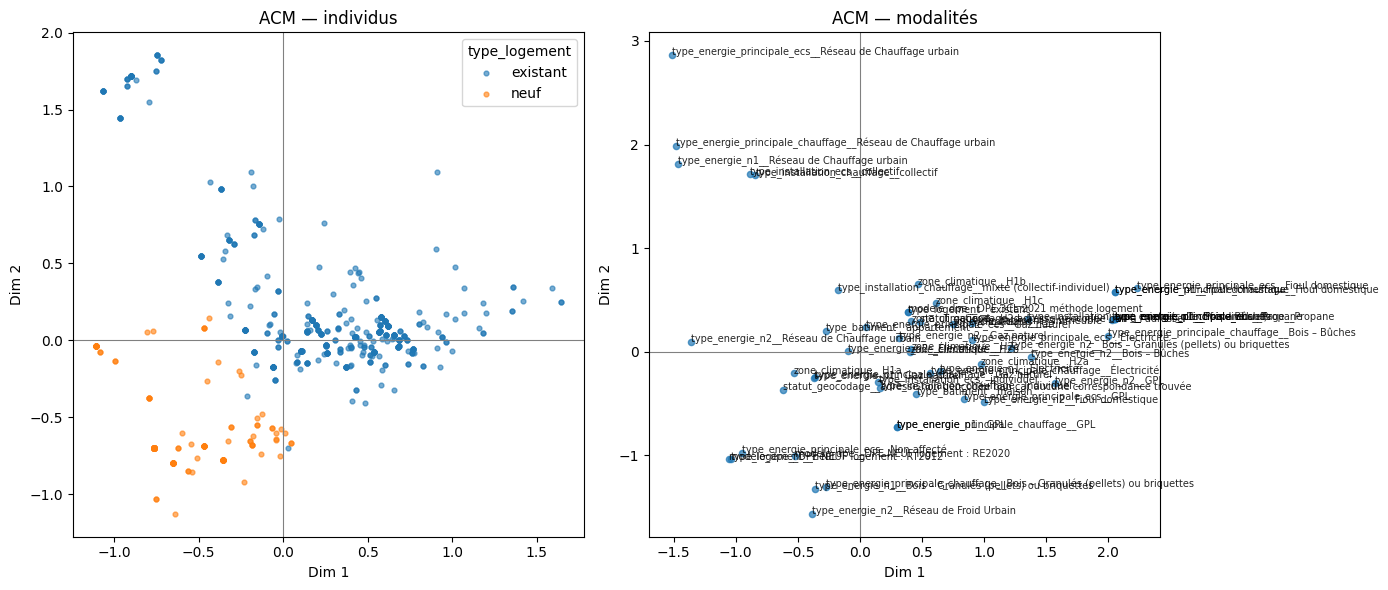

Coordonnées modalités (extrait) :


,0,1,2,3,4
modele_dpe__DPE 3CL 2021 méthode logement,0.386487,0.384150,-0.008508,-0.071133,-0.004384
modele_dpe__DPE NEUF logement : RE2020,-0.520280,-1.002666,-0.082323,-0.136387,-0.395606
modele_dpe__DPE NEUF logement : RT2012,-1.051876,-1.034784,0.025229,0.198729,0.020805
statut_geocodage__adresse géocodée ban à l'adresse,0.481979,0.290073,-0.055135,-0.099531,-0.060103
statut_geocodage__adresse non géocodée ban car aucune correspondance trouvée,-0.618997,-0.372535,0.070808,0.127826,0.077189
type_batiment__appartement,-0.277537,0.204522,0.031414,-0.051411,-0.085313
type_batiment__immeuble,0.905587,0.280192,-0.144972,-0.110778,-0.304141
type_batiment__maison,0.454034,-0.408741,-0.048068,0.105903,0.185156
type_energie_n1__Bois – Bûches,2.031702,0.305593,-0.428106,-0.626108,-1.278751
type_energie_n1__Bois – Granulés (pellets) ou briquettes,-0.364526,-1.329463,-0.141460,0.559577,-0.047257


In [13]:
import matplotlib.pyplot as plt
import prince

# Variables déjà traitées en ordinal → exclues de l'ACM
ORDINAL_COLS = list(ORDINAL_MAPS.keys()) if "ORDINAL_MAPS" in dir() else [
    "etiquette_dpe",
    "etiquette_ges",
    "qualite_isolation_enveloppe",
    "qualite_isolation_menuiseries",
    "qualite_isolation_murs",
    "qualite_isolation_plancher_bas",
    "indicateur_confort_ete",
    "classe_altitude",
    "classe_inertie_batiment",
    "periode_construction",
]

# Textes libres / ids / dates peu adaptés à l'ACM
ACM_EXCLUDE = EXCLUDE | set(ORDINAL_COLS) | {
    c for c in df.columns if str(c).startswith("date_")
} | {
    "description_installation_chauffage_n1",
    "description_installation_chauffage_n2",
    "description_generateur_chauffage_n1_installation_n1",
    "description_generateur_chauffage_n1_installation_n2",
    "description_generateur_chauffage_n2_installation_n1",
    "description_generateur_froid",
    "configuration_installation_chauffage_n1",
    "configuration_installation_chauffage_n2",
    "type_generateur_n1_ecs_n1",
    "type_generateur_froid",
    "type_emetteur_installation_chauffage_n1",
    "type_emetteur_installation_chauffage_n2",
    "type_ventilation",
    "typologie_logement",
    "methode_application_dpe",
    "categorie_enr",
    "periode_installation_generateur_froid",
    "position_logement_dans_immeuble",
    "systeme_production_electricite_origine_renouvelable",
}

# Qualitatives restantes, cardinalité raisonnable pour l'ACM
MAX_MODALITES = 15
cat_acm = []
for c in df.select_dtypes(exclude="number").columns:
    if c in ACM_EXCLUDE or c == TARGET:
        continue
    nmod = df[c].nunique(dropna=True)
    if 2 <= nmod <= MAX_MODALITES:
        cat_acm.append(c)

print(f"Variables qualitatives non ordinales retenues ({len(cat_acm)}) :")
print(cat_acm)

df_acm = df[cat_acm].copy()
# Modalités manquantes = catégorie explicite (requis pour l'ACM)
df_acm = df_acm.astype("object").fillna("Manquant")

mca = prince.MCA(n_components=5, random_state=42)
mca = mca.fit(df_acm)

print("\nInertie / valeurs propres :")
display(mca.eigenvalues_summary)

# Coordonnées individus et modalités (plan 1-2)
coords_ind = mca.row_coordinates(df_acm)
coords_mod = mca.column_coordinates(df_acm)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Nuage des individus (coloré par type_logement si dispo)
ax = axes[0]
if "type_logement" in df.columns:
    for label, grp in coords_ind.groupby(df.loc[df_acm.index, "type_logement"]):
        ax.scatter(grp.iloc[:, 0], grp.iloc[:, 1], s=12, alpha=0.6, label=str(label))
    ax.legend(title="type_logement")
else:
    ax.scatter(coords_ind.iloc[:, 0], coords_ind.iloc[:, 1], s=12, alpha=0.5)
ax.axhline(0, color="grey", lw=0.8)
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("Dim 1")
ax.set_ylabel("Dim 2")
ax.set_title("ACM — individus")

# Nuage des modalités
ax = axes[1]
ax.scatter(coords_mod.iloc[:, 0], coords_mod.iloc[:, 1], s=20, alpha=0.7)
for name, row in coords_mod.iterrows():
    ax.annotate(str(name), (row.iloc[0], row.iloc[1]), fontsize=7, alpha=0.85)
ax.axhline(0, color="grey", lw=0.8)
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("Dim 1")
ax.set_ylabel("Dim 2")
ax.set_title("ACM — modalités")

plt.tight_layout()
plt.show()

print("Coordonnées modalités (extrait) :")
display(coords_mod.head(20))
